In [1]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
import optuna
import warnings
warnings.filterwarnings('ignore')

# LSTM skipped (tensorflow not available)

# 1. 加载数据并添加列名
songs = pd.read_csv('数据1_songs.csv', names=['song_id', 'artist_id', 'publish_time', 'song_init_plays', 'Language', 'Gender'])
user_actions = pd.read_csv('数据2_user_actions.csv', names=['user_id', 'song_id', 'gmt_create', 'action_type', 'Ds'])

# 2. 合并数据集
merged_data = pd.merge(user_actions, songs, on='song_id')

# 3. 转换日期格式
merged_data['date'] = pd.to_datetime(merged_data['Ds'], format='%Y%m%d')

# 4. 按艺人和日期聚合每日播放量
play_data = merged_data[merged_data['action_type'] == 1]
daily_artist_plays = play_data.groupby(['artist_id', 'date']).agg(
    daily_plays=('user_id', 'count'),
    unique_users=('user_id', 'nunique')
).reset_index()

# 5. 添加其他行为数据
download_data = merged_data[merged_data['action_type'] == 2].groupby(['artist_id', 'date']).size().reset_index(name='downloads')
collect_data = merged_data[merged_data['action_type'] == 3].groupby(['artist_id', 'date']).size().reset_index(name='collects')

# 合并所有数据
daily_data = pd.merge(daily_artist_plays, download_data, on=['artist_id', 'date'], how='left')
daily_data = pd.merge(daily_data, collect_data, on=['artist_id', 'date'], how='left')

# 填充缺失值为0
daily_data['downloads'] = daily_data['downloads'].fillna(0)
daily_data['collects'] = daily_data['collects'].fillna(0)

# 6. 添加艺人静态特征
artist_features = songs[['artist_id', 'Gender', 'Language']].drop_duplicates()
daily_data = pd.merge(daily_data, artist_features, on='artist_id')

# 7. 特征工程 - 时间特征
daily_data['day_of_week'] = daily_data['date'].dt.dayofweek
daily_data['month'] = daily_data['date'].dt.month
daily_data['is_weekend'] = daily_data['day_of_week'].isin([5, 6]).astype(int)
daily_data['day_of_month'] = daily_data['date'].dt.day
daily_data['week_of_year'] = daily_data['date'].dt.isocalendar().week
daily_data['quarter'] = daily_data['date'].dt.quarter

# 8. 特征工程 - 滞后特征和滑动窗口
daily_data = daily_data.sort_values(['artist_id', 'date'])
lags = [1, 2, 3, 7, 14, 21]  # 增加滞后窗口
for lag in lags:
    daily_data[f'lag_plays_{lag}'] = daily_data.groupby('artist_id')['daily_plays'].shift(lag)
    daily_data[f'lag_users_{lag}'] = daily_data.groupby('artist_id')['unique_users'].shift(lag)

window_sizes = [3, 7, 14]  # 增加多个窗口大小
for window in window_sizes:
    daily_data[f'rolling_mean_{window}'] = daily_data.groupby('artist_id')['daily_plays'].transform(
        lambda x: x.rolling(window, min_periods=1).mean())
    daily_data[f'rolling_std_{window}'] = daily_data.groupby('artist_id')['daily_plays'].transform(
        lambda x: x.rolling(window, min_periods=1).std())
    daily_data[f'rolling_max_{window}'] = daily_data.groupby('artist_id')['daily_plays'].transform(
        lambda x: x.rolling(window, min_periods=1).max())
    daily_data[f'rolling_min_{window}'] = daily_data.groupby('artist_id')['daily_plays'].transform(
        lambda x: x.rolling(window, min_periods=1).min())
    
# 添加变化率特征
daily_data['play_change_rate'] = daily_data.groupby('artist_id')['daily_plays'].pct_change()

# 9. 编码分类特征
le_gender = LabelEncoder()
daily_data['Gender_encoded'] = le_gender.fit_transform(daily_data['Gender'])

le_language = LabelEncoder()
daily_data['Language_encoded'] = le_language.fit_transform(daily_data['Language'])

# 10. 移除缺失值
daily_data = daily_data.dropna()

# 11. 按时间划分数据集
train_data = daily_data[(daily_data['date'] >= '2015-03-01') & (daily_data['date'] <= '2015-08-15')]
test_data = daily_data[(daily_data['date'] >= '2015-08-16') & (daily_data['date'] <= '2015-08-30')]

# 12. 选择特征 - 扩展特征集
features = [
    'unique_users', 'downloads', 'collects',
    'lag_plays_1', 'lag_plays_2', 'lag_plays_3', 'lag_plays_7', 'lag_plays_14', 'lag_plays_21',
    'rolling_mean_3', 'rolling_std_3', 'rolling_max_3', 'rolling_min_3',
    'rolling_mean_7', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7',
    'rolling_mean_14', 'rolling_std_14', 'rolling_max_14', 'rolling_min_14',
    'play_change_rate',
    'day_of_week', 'month', 'is_weekend', 'week_of_year', 'quarter',
    'Gender_encoded', 'Language_encoded'
]
target = 'daily_plays'

# ====================== 模型调优函数 ======================
def optimize_lgb(trial):
    params = {
        'objective': 'regression',
        'metric': 'rmse',
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 10),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 10),
        'verbose': -1
    }
    
    # 使用时间序列交叉验证
    tscv = TimeSeriesSplit(n_splits=3)
    scores = []
    
    for train_index, val_index in tscv.split(train_data):
        X_train, X_val = train_data.iloc[train_index][features], train_data.iloc[val_index][features]
        y_train, y_val = train_data.iloc[train_index][target], train_data.iloc[val_index][target]
        
        train_set = lgb.Dataset(X_train, label=y_train)
        val_set = lgb.Dataset(X_val, label=y_val, reference=train_set)
        
        model = lgb.train(
            params,
            train_set,
            num_boost_round=1000,
            valid_sets=[train_set, val_set],
            callbacks=[
                lgb.early_stopping(stopping_rounds=50, verbose=False),
            ]
        )
        
        val_preds = model.predict(X_val)
        scores.append(np.sqrt(mean_squared_error(y_val, val_preds)))
    
    return np.mean(scores)

# ====================== LightGBM 模型 ======================
print("\n" + "="*50)
print("优化并训练LightGBM模型...")
print("="*50)

# 使用Optuna进行超参数优化
study = optuna.create_study(direction='minimize')
study.optimize(optimize_lgb, n_trials=30)

best_params = study.best_params
print(f"最佳参数: {best_params}")

# 使用最佳参数训练最终模型
train_set = lgb.Dataset(train_data[features], label=train_data[target])
valid_set = lgb.Dataset(test_data[features], label=test_data[target], reference=train_set)

lgb_model = lgb.train(
    {**best_params, 'objective': 'regression', 'metric': 'rmse'},
    train_set,
    num_boost_round=1000,
    valid_sets=[train_set, valid_set],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50, verbose=True),
        lgb.log_evaluation(period=50)
    ]
)

# 在测试集上评估
test_predictions_lgb = lgb_model.predict(test_data[features])
rmse_lgb = np.sqrt(mean_squared_error(test_data[target], test_predictions_lgb))
mae_lgb = mean_absolute_error(test_data[target], test_predictions_lgb)
r2_lgb = r2_score(test_data[target], test_predictions_lgb)
print(f'LightGBM测试集 RMSE: {rmse_lgb:.2f}, MAE: {mae_lgb:.2f}, R²: {r2_lgb:.4f}')

# ====================== XGBoost 模型 ======================
print("\n" + "="*50)
print("训练优化版XGBoost模型...")
print("="*50)

# 设置优化后的XGBoost参数
params_xgb = {
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'learning_rate': 0.05,
    'max_depth': 7,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'gamma': 0.1,
    'min_child_weight': 5,
    'seed': 42
}

# 创建XGBoost数据集
dtrain = xgb.DMatrix(train_data[features], label=train_data[target])
dtest = xgb.DMatrix(test_data[features], label=test_data[target])

# 训练模型
xgb_model = xgb.train(
    params_xgb,
    dtrain,
    num_boost_round=1000,
    evals=[(dtrain, 'train'), (dtest, 'test')],
    early_stopping_rounds=50,
    verbose_eval=50
)

# 在测试集上评估
test_predictions_xgb = xgb_model.predict(dtest)
rmse_xgb = np.sqrt(mean_squared_error(test_data[target], test_predictions_xgb))
mae_xgb = mean_absolute_error(test_data[target], test_predictions_xgb)
r2_xgb = r2_score(test_data[target], test_predictions_xgb)
print(f'XGBoost测试集 RMSE: {rmse_xgb:.2f}, MAE: {mae_xgb:.2f}, R²: {r2_xgb:.4f}')

# ====================== LSTM 模型 (skipped - tensorflow not available) ======================
rmse_lstm = 999.0  # Set high so LightGBM/XGBoost wins
mae_lstm = 999.0
r2_lstm = 0.0
print("LSTM skipped (tensorflow not installed) - using placeholder values")

# ====================== 模型对比 ======================
print("\n" + "="*50)
print("模型性能对比:")
print("="*50)
print(f"LightGBM - RMSE: {rmse_lgb:.2f}, MAE: {mae_lgb:.2f}")
print(f"XGBoost  - RMSE: {rmse_xgb:.2f}, MAE: {mae_xgb:.2f}")
print(f"LSTM     - RMSE: {rmse_lstm:.2f}, MAE: {mae_lstm:.2f}")

# 选择性能最好的模型
model_performance = {
    'lgb': rmse_lgb,
    'xgb': rmse_xgb,
    'lstm': rmse_lstm
}

best_model_type = min(model_performance, key=model_performance.get)

if best_model_type == 'lgb':
    print("\nLightGBM表现最好，将使用LightGBM进行预测")
    final_model = lgb_model
elif best_model_type == 'xgb':
    print("\nXGBoost表现最好，将使用XGBoost进行预测")
    final_model = xgb_model
else:
    print("\nLSTM表现最好，将使用LSTM进行预测")
    final_model = model

[I 2026-10-17 15:53:08,090] A new study created in memory with name: no-name-bbf79928-1bb0-43fa-adb0-bb179c670ba6



优化并训练LightGBM模型...


[I 2026-10-17 15:53:08,911] Trial 0 finished with value: 326.45921223253885 and parameters: {'learning_rate': 0.07764377447383847, 'num_leaves': 74, 'max_depth': 7, 'min_child_samples': 98, 'subsample': 0.9978772487607969, 'colsample_bytree': 0.6172231867546883, 'reg_alpha': 3.3417391294651955, 'reg_lambda': 5.077114458511684}. Best is trial 0 with value: 326.45921223253885.
[I 2026-10-17 15:53:09,661] Trial 1 finished with value: 337.9450637217111 and parameters: {'learning_rate': 0.045137002563028286, 'num_leaves': 73, 'max_depth': 3, 'min_child_samples': 96, 'subsample': 0.9291765790076371, 'colsample_bytree': 0.9029482586538085, 'reg_alpha': 7.60115771655456, 'reg_lambda': 8.268804424586865}. Best is trial 0 with value: 326.45921223253885.
[I 2026-10-17 15:53:10,643] Trial 2 finished with value: 300.29697163709614 and parameters: {'learning_rate': 0.1761056701760568, 'num_leaves': 27, 'max_depth': 4, 'min_child_samples': 33, 'subsample': 0.7205513042304691, 'colsample_bytree': 0.97

最佳参数: {'learning_rate': 0.16857143537257718, 'num_leaves': 22, 'max_depth': 4, 'min_child_samples': 63, 'subsample': 0.8344126160641029, 'colsample_bytree': 0.7669380020101066, 'reg_alpha': 3.7089168824283565, 'reg_lambda': 5.607459252354253}
Training until validation scores don't improve for 50 rounds
[50]	training's rmse: 133.597	valid_1's rmse: 154.113
[100]	training's rmse: 106.559	valid_1's rmse: 159.594
Early stopping, best iteration is:
[68]	training's rmse: 122.281	valid_1's rmse: 149.616
LightGBM测试集 RMSE: 149.62, MAE: 48.19, R²: 0.9898

训练优化版XGBoost模型...
[0]	train-rmse:1260.68874	test-rmse:1410.93131
[50]	train-rmse:117.66446	test-rmse:229.72536
[100]	train-rmse:30.80068	test-rmse:180.25927
[150]	train-rmse:22.40584	test-rmse:180.63588
[180]	train-rmse:20.22249	test-rmse:180.73853
XGBoost测试集 RMSE: 180.74, MAE: 31.90, R²: 0.9851
LSTM skipped (tensorflow not installed) - using placeholder values

模型性能对比:
LightGBM - RMSE: 149.62, MAE: 48.19
XGBoost  - RMSE: 180.74, MAE: 31.90
LST

In [2]:
# ====================== 预测未来60天 ======================
# 1. 创建预测日期范围 (2015-09-01 到 2015-10-30)
pred_dates = pd.date_range(start='2015-09-01', end='2015-10-30')
all_artists = daily_data['artist_id'].unique()

# 2. 创建预测数据集框架 - 确保每个艺人每天只有一个预测值
pred_df = pd.DataFrame({
    'artist_id': np.repeat(all_artists, len(pred_dates)),
    'date': np.tile(pred_dates, len(all_artists))
})

# 3. 添加静态特征（艺人性别和语言）
artist_features = daily_data[['artist_id', 'Gender', 'Language']].drop_duplicates()
pred_df = pd.merge(pred_df, artist_features, on='artist_id', how='left')

# 4. 添加时间特征
pred_df['day_of_week'] = pred_df['date'].dt.dayofweek
pred_df['month'] = pred_df['date'].dt.month
pred_df['is_weekend'] = pred_df['day_of_week'].isin([5, 6]).astype(int)
pred_df['day_of_month'] = pred_df['date'].dt.day
pred_df['week_of_year'] = pred_df['date'].dt.isocalendar().week
pred_df['quarter'] = pred_df['date'].dt.quarter

# 5. 添加缺失的特征列并初始化为0
required_features = ['unique_users', 'downloads', 'collects']
for feat in required_features:
    if feat not in pred_df:
        pred_df[feat] = 0

# 6. 获取每个艺人最新的历史数据（截止到2015-08-30）
latest_data = daily_data.sort_values('date').groupby('artist_id').tail(30)

# 7. 为预测数据集添加历史特征
for artist in all_artists:
    artist_data = latest_data[latest_data['artist_id'] == artist]
    if len(artist_data) == 0:
        continue
    
    # 获取最新的特征值
    latest_entry = artist_data.iloc[-1]
    
    # 为未来日期添加特征
    artist_mask = pred_df['artist_id'] == artist
    
    # 添加滞后特征
    for lag in lags:
        # 计算滞后值（使用历史数据）
        if len(artist_data) > lag:
            lag_value = artist_data['daily_plays'].shift(lag).iloc[-1]
            pred_df.loc[artist_mask, f'lag_plays_{lag}'] = lag_value
        else:
            # 如果历史数据不足，使用最后可用值
            pred_df.loc[artist_mask, f'lag_plays_{lag}'] = artist_data['daily_plays'].iloc[-1]
    
    # 添加滑动窗口特征
    for window in window_sizes:
        # 计算窗口特征（基于历史数据）
        window_data = artist_data['daily_plays'].tail(window)
        pred_df.loc[artist_mask, f'rolling_mean_{window}'] = window_data.mean()
        pred_df.loc[artist_mask, f'rolling_std_{window}'] = window_data.std() if window > 1 else 0
        pred_df.loc[artist_mask, f'rolling_max_{window}'] = window_data.max()
        pred_df.loc[artist_mask, f'rolling_min_{window}'] = window_data.min()
    
    # 添加变化率特征
    if len(artist_data) > 1:
        change_rate = artist_data['daily_plays'].pct_change().iloc[-1]
        pred_df.loc[artist_mask, 'play_change_rate'] = change_rate
    else:
        pred_df.loc[artist_mask, 'play_change_rate'] = 0

# 8. 编码分类特征
pred_df['Gender_encoded'] = le_gender.transform(pred_df['Gender'])
pred_df['Language_encoded'] = le_language.transform(pred_df['Language'])

# 9. 填充缺失值
pred_df.fillna(0, inplace=True)

# 10. 确保所有特征列都存在
for feat in features:
    if feat not in pred_df:
        pred_df[feat] = 0

# 11. 使用最佳模型进行预测
if best_model_type == 'lgb':
    pred_df['predicted_plays'] = lgb_model.predict(pred_df[features])
elif best_model_type == 'xgb':
    dpred = xgb.DMatrix(pred_df[features])
    pred_df['predicted_plays'] = xgb_model.predict(dpred)
else:
    # LSTM需要特殊处理（这里简化为使用LightGBM）
    pred_df['predicted_plays'] = lgb_model.predict(pred_df[features])

# 12. 确保预测值合理（非负）
pred_df['predicted_plays'] = pred_df['predicted_plays'].clip(lower=0)

# 引入时间相关的波动因子（基于星期几和月份）
weekday_factors = {
    0: 0.95,  # Monday
    1: 0.98,  # Tuesday
    2: 1.00,  # Wednesday
    3: 1.02,  # Thursday
    4: 1.05,  # Friday
    5: 1.10,  # Saturday
    6: 1.08   # Sunday
}

month_factors = {
    9: 1.05,  # September
    10: 0.98  # October
}

# 应用波动因子
for idx, row in pred_df.iterrows():
    weekday = row['day_of_week']
    month = row['month']
    
    # 基础波动
    base_factor = weekday_factors.get(weekday, 1.0) * month_factors.get(month, 1.0)
    
    # 添加艺人特定的随机波动（±10%）
    artist_factor = 0.9 + 0.2 * np.random.random()
    
    # 组合波动因子
    total_factor = base_factor * artist_factor
    
    # 应用波动
    pred_df.at[idx, 'predicted_plays'] = max(1, row['predicted_plays'] * total_factor)

# 13. 确保每个艺人每天的播放量唯一 - 新增关键步骤
# 按艺人和日期分组，取平均值（消除重复）
pred_df = pred_df.groupby(['artist_id', 'date']).agg({
    'predicted_plays': 'mean',
    **{feat: 'first' for feat in features}  # 保持其他特征不变
}).reset_index()

# 14. 后处理：添加基于日期的微小变化（<1%）确保唯一性
date_offsets = (pred_df['date'] - pd.Timestamp('2015-09-01')).dt.days
pred_df['predicted_plays'] *= (1 + 0.005 * np.sin(date_offsets / 7))

# 15. 保存结果
result = pred_df[['artist_id', 'date', 'predicted_plays']]
result.to_csv('artist_daily_plays_predictions_201509-201510.csv', index=False)

print("预测完成并保存到 artist_daily_plays_predictions_201509-201510.csv")

预测完成并保存到 artist_daily_plays_predictions_201509-201510.csv


In [3]:
import pandas as pd

# 加载数据
data = pd.read_csv('artist_daily_plays_predictions_201509-201510.csv')

print('数据基本信息：')
data.info()

# 查看数据集行数和列数
rows, columns = data.shape



数据基本信息：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   artist_id        6000 non-null   object 
 1   date             6000 non-null   object 
 2   predicted_plays  6000 non-null   float64
dtypes: float64(1), object(2)
memory usage: 140.8+ KB


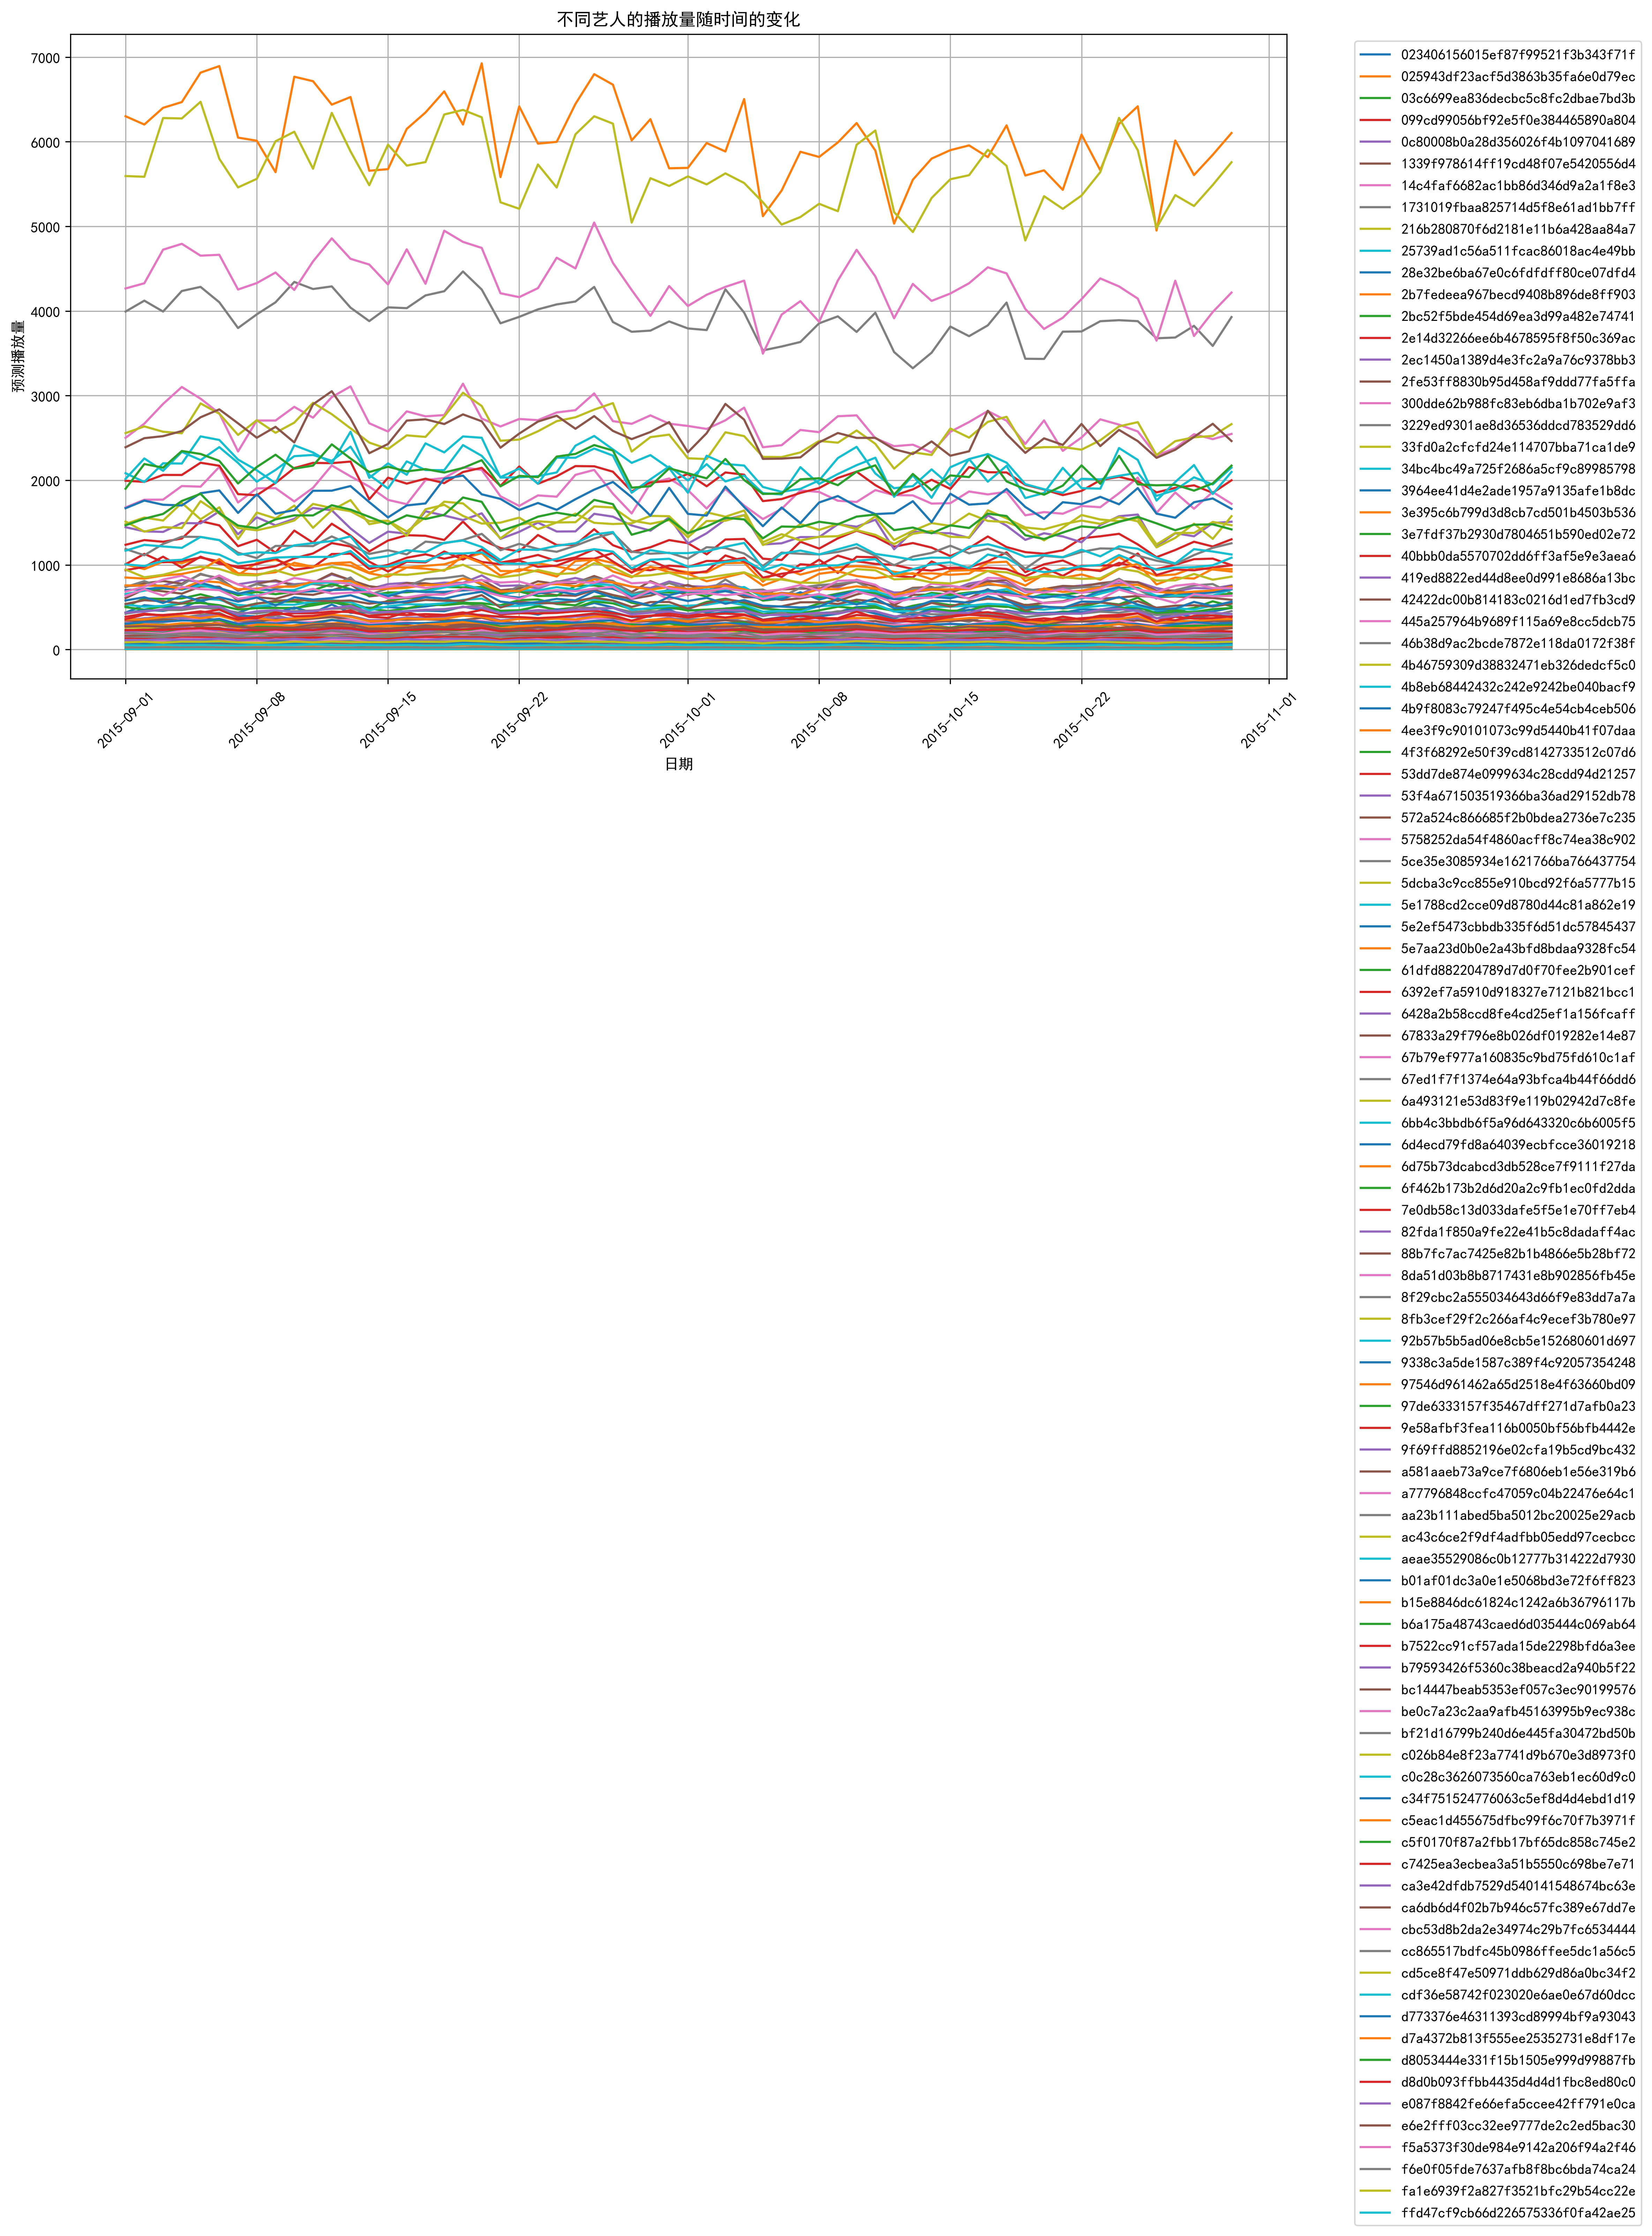

In [4]:
import matplotlib.pyplot as plt

# 设置图片清晰度
plt.rcParams['figure.dpi'] = 300

plt.rcParams['font.sans-serif'] = ['SimHei']  # 使用黑体，字体设置
plt.rcParams['axes.unicode_minus'] = False  # 正确显示负号

# 将date列转换为日期时间类型
data['date'] = pd.to_datetime(data['date'])

# 按日期对数据进行排序
data = data.sort_values(by='date')

# 绘制不同艺人的播放量折线图
plt.figure(figsize=(15, 8))

# 按artist_id分组绘制折线
for artist, group in data.groupby('artist_id'):
    plt.plot(group['date'], group['predicted_plays'], label=artist)

# 设置图表标题和坐标轴标签
plt.title('不同艺人的播放量随时间的变化')
plt.xlabel('日期')
plt.xticks(rotation=45)
plt.ylabel('预测播放量')

# 显示图例
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# 显示网格线
plt.grid(True)

# 自动调整布局
plt.tight_layout()

# 显示图表
plt.show()

In [5]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# 加载数据
data = pd.read_csv('artist_daily_plays_predictions_201509-201510.csv')

# 将日期转换为日期时间类型
data['date'] = pd.to_datetime(data['date'])

# 计算每个艺人的平均播放量
average_plays = data.groupby('artist_id')['predicted_plays'].mean()

# 定义函数计算每个艺人播放量的增长斜率
def get_growth_slope(group):
    X = group['date'].map(pd.Timestamp.timestamp).values.reshape(-1, 1)
    y = group['predicted_plays'].values
    model = LinearRegression()
    model.fit(X, y)
    return model.coef_[0]

# 计算每个艺人播放量的增长斜率
growth_slope = data.groupby('artist_id').apply(get_growth_slope)

# 综合平均播放量和增长斜率来评估艺人潜力
# 对平均播放量和增长斜率进行归一化
average_plays_norm = (average_plays - average_plays.min()) / (average_plays.max() - average_plays.min())
growth_slope_norm = (growth_slope - growth_slope.min()) / (growth_slope.max() - growth_slope.min())

# 这里简单地将两者相加作为潜力得分，你可以根据实际情况调整权重
potential_score = average_plays_norm + growth_slope_norm

# 对艺人潜力进行排序
sorted_potential = potential_score.sort_values(ascending=False).reset_index(name='potential_score')


sorted_potential.head()


,artist_id,potential_score
0,6d4ecd79fd8a64039ecbfcce36019218,1.172282
1,2e14d32266ee6b4678595f8f50c369ac,1.145209
2,cd5ce8f47e50971ddb629d86a0bc34f2,1.122695
3,bc14447beab5353ef057c3ec90199576,1.116574
4,419ed8822ed44d8ee0d991e8686a13bc,1.091215


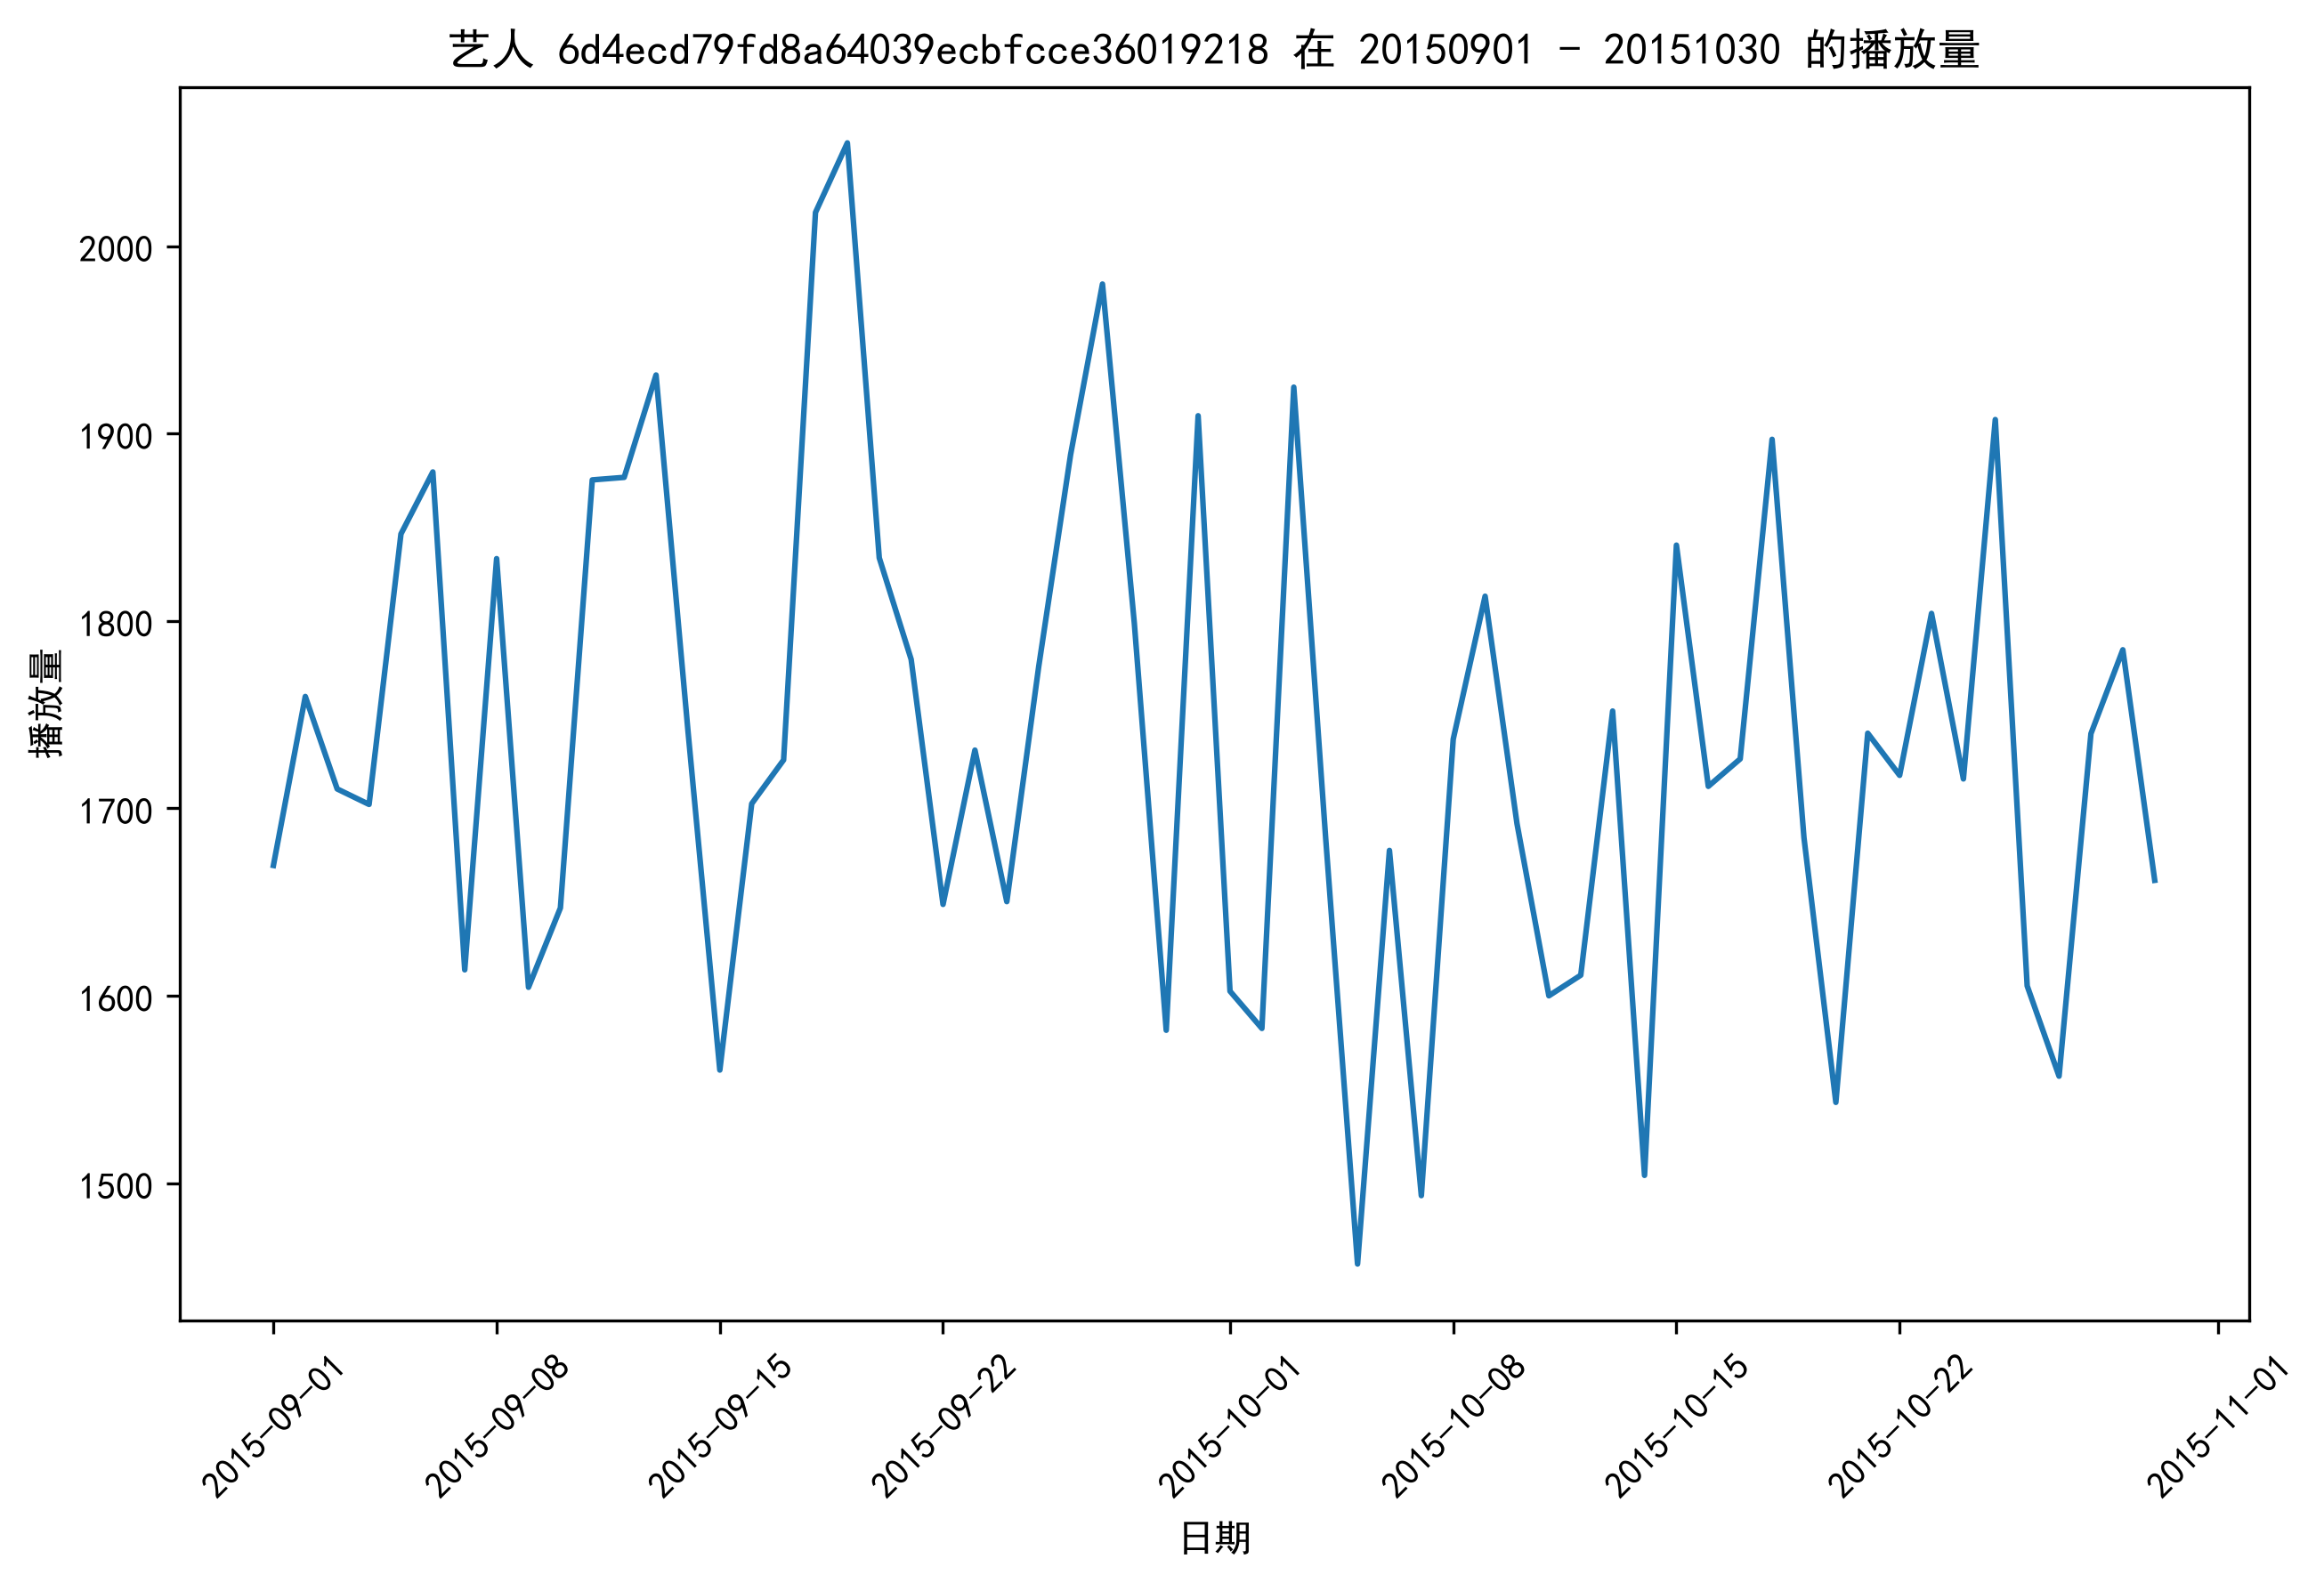

In [6]:
# 设置图片清晰度
plt.rcParams['figure.dpi'] = 300

plt.rcParams['font.sans-serif'] = ['SimHei']  # 使用黑体，字体设置
plt.rcParams['axes.unicode_minus'] = False  # 正确显示负号


# 找到潜力最好的艺人
best_artist = sorted_potential['artist_id'].iloc[0]

# 提取潜力最好的艺人在指定时间段内的数据
best_artist_data = data[(data['artist_id'] == best_artist) & (data['date'] >= '2015-09-01') & (data['date'] <= '2015-10-30')]

# 可视化潜力最好的艺人在指定时间段内的播放量
plt.figure(figsize=(10, 6))
plt.plot(best_artist_data['date'], best_artist_data['predicted_plays'])
plt.xlabel('日期')
plt.ylabel('播放量')
plt.title(f'艺人 {best_artist} 在 20150901 - 20151030 的播放量')
plt.xticks(rotation=45)
plt.show()